# Gauss–Newton法とLevenberg–Marquardt法の違い

## 概要

Gauss–Newton法とLevenberg–Marquardt法は、非線形最小二乗問題を解く反復法である。どちらも残差を線形化するが、後者は減衰項を加えて更新量を調整する。本記事では更新式を導出し、1変数の計算、2変数の反復、指数関数の当てはめをPythonで比較する。以下ではGN法、LM法と略記する。

### 実行環境

仮想環境は`wa-src(3.14.6)`、Pythonは3.14.6である。使用ライブラリとOSは次のセルで確認する。セルを上から順に実行すると、作業ディレクトリの`104_nb_files`にグラフをSVG形式で保存し、Notebookにも埋め込む。小数の表示は有効数字3桁とし、内部の計算値は丸めない。

In [1]:
import platform
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from IPython.display import Math, display
from matplotlib.ticker import FuncFormatter, MaxNLocator, NullFormatter
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.optimize import least_squares

%matplotlib inline
# SVGを優先し、ビューア互換用のPNGもNotebook内に埋め込む。
set_matplotlib_formats("svg", "png")

print("実行環境: wa-src(3.14.6)")
print("Python:", platform.python_version())
print("OS:", platform.system(), platform.release())
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
assert platform.python_version() == "3.14.6"


def sig3(value):
    """表示だけを有効数字3桁にする。末尾の0も残す。"""
    return f"{float(value):#.3g}"


np.set_printoptions(formatter={"float_kind": sig3})
plt.rcParams.update({"font.size": 11, "axes.grid": True, "grid.alpha": 0.250,
                     "svg.fonttype": "none", "svg.hashsalt": "104"})
output_dir = Path("104_nb_files")
output_dir.mkdir(exist_ok=True)
colors = {"GN": "#c85a2a", "LM": "#176c9e"}


def save_figure(fig, filename, integer_x=False):
    """目盛りを整えてSVGを保存し、Notebookにも表示する。"""
    for ax in fig.axes:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: sig3(x)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: sig3(x)))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.yaxis.set_minor_formatter(NullFormatter())
        if integer_x:
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
            ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.0f}"))
    fig.savefig(output_dir / filename, format="svg", bbox_inches="tight",
                metadata={"Date": None})
    plt.show()
    plt.close(fig)

実行環境: wa-src(3.14.6)
Python: 3.14.6
OS: Darwin 25.5.0
NumPy: 2.5.4
SciPy: 1.18.1
Matplotlib: 3.11.2


## 1. 非線形最小二乗問題

観測値$y_i$をモデル$f(t_i;\mathbf{x})$で近似する。未知のパラメータを$\mathbf{x}\in\mathbb{R}^n$、観測数を$m$とし、残差の符号を「モデル値から観測値を引く」と決める。

$$
r_i(\mathbf{x})=f(t_i;\mathbf{x})-y_i,\qquad
\mathbf{r}(\mathbf{x})=\begin{bmatrix}r_1(\mathbf{x})&\cdots&r_m(\mathbf{x})\end{bmatrix}^{\mathsf T}.
$$

最小化する関数は残差の二乗和の半分である。係数$1/2$は微分を簡単にするためのもので、最小点を変えない。

<div>
$$
F(\mathbf{x})=\frac12\sum_{i=1}^m r_i(\mathbf{x})^2
=\frac12\mathbf{r}(\mathbf{x})^{\mathsf T}\mathbf{r}(\mathbf{x}).
$$
</div>

ヤコビ行列$\mathbf{J}\in\mathbb{R}^{m\times n}$の成分は$J_{ij}=\partial r_i/\partial x_j$である。成分ごとに微分すると、

$$
\begin{aligned}
\frac{\partial F}{\partial x_j}
&=\frac12\sum_i 2r_i\frac{\partial r_i}{\partial x_j}
=\sum_i J_{ij}r_i,\\
\mathbf{g}=\nabla F&=\mathbf{J}^{\mathsf T}\mathbf{r},\\
\frac{\partial^2 F}{\partial x_k\partial x_j}
&=\sum_i\left(\frac{\partial r_i}{\partial x_k}\frac{\partial r_i}{\partial x_j}
+r_i\frac{\partial^2 r_i}{\partial x_k\partial x_j}\right),\\
\nabla^2 F&=\mathbf{J}^{\mathsf T}\mathbf{J}+\sum_i r_i\nabla^2 r_i.
\end{aligned}
$$

Newton法はこのヘッセ行列全体を使う。GN法が省略するのは、最後の残差と残差の2階微分の積を足した項である。

## 2. Gauss–Newton法の導出

現在の点$\mathbf{x}$からの変化を$\mathbf{p}$とする。残差が十分滑らかなら、1次のTaylor展開は次の形になる。以後、$\mathbf{r}$と$\mathbf{J}$は現在の点で評価する。

$$
\mathbf{r}(\mathbf{x}+\mathbf{p})
=\mathbf{r}+\mathbf{J}\mathbf{p}+O(\|\mathbf{p}\|^2).
$$

2次以上の残差項を除き、局所的な二次関数$q$を作る。

$$
\begin{aligned}
q(\mathbf{p})
&=\frac12\|\mathbf{r}+\mathbf{J}\mathbf{p}\|^2\\
&=\frac12(\mathbf{r}+\mathbf{J}\mathbf{p})^{\mathsf T}
(\mathbf{r}+\mathbf{J}\mathbf{p})\\
&=\frac12\mathbf{r}^{\mathsf T}\mathbf{r}
+\frac12\mathbf{r}^{\mathsf T}\mathbf{J}\mathbf{p}
+\frac12\mathbf{p}^{\mathsf T}\mathbf{J}^{\mathsf T}\mathbf{r}
+\frac12\mathbf{p}^{\mathsf T}\mathbf{J}^{\mathsf T}\mathbf{J}\mathbf{p}\\
&=F(\mathbf{x})+\mathbf{g}^{\mathsf T}\mathbf{p}
+\frac12\mathbf{p}^{\mathsf T}\mathbf{J}^{\mathsf T}\mathbf{J}\mathbf{p}.
\end{aligned}
$$

中央の二つのスカラーは転置しても同じなので、まとめられる。$\mathbf{p}$で微分して0と置くと、

<div>
$$
\begin{aligned}
\nabla_{\mathbf{p}}q&=\mathbf{J}^{\mathsf T}\mathbf{r}
+\mathbf{J}^{\mathsf T}\mathbf{J}\mathbf{p}=\mathbf{0},\\
\mathbf{J}^{\mathsf T}\mathbf{J}\mathbf{p}_{\mathrm{GN}}
&=-\mathbf{J}^{\mathsf T}\mathbf{r},\\
\mathbf{x}_{k+1}&=\mathbf{x}_k+\mathbf{p}_{\mathrm{GN}}.
\end{aligned}
$$
</div>

$\mathbf{J}$が列フルランクなら更新量は一意である。残差が小さい解の近くでは省略した項も小さくなりやすい。ただし残差の2階微分の大きさにも依存する。解で残差が0、ヤコビ行列が列フルランクで十分滑らかなら、十分近い初期値から局所的に2次収束する。

$q$を下げても実際の$F$が下がるとは限らない。本記事のGN法は更新量をそのまま加える。直線探索で更新量を縮めるGN法もある。

## 3. Levenberg–Marquardt法の導出

LM法では、更新量の大きさに罰則を加える。まず単位行列$\mathbf{I}$を使う形を考える。

$$
\begin{aligned}
q_\lambda(\mathbf{p})
&=q(\mathbf{p})+\frac{\lambda}{2}\|\mathbf{p}\|^2,\qquad\lambda>0,\\
\nabla_{\mathbf{p}}q_\lambda
&=\mathbf{J}^{\mathsf T}\mathbf{r}+\mathbf{J}^{\mathsf T}\mathbf{J}\mathbf{p}
+\lambda\mathbf{p}=\mathbf{0}.
\end{aligned}
$$

よって更新式は次のようになる。

<div>
$$
(\mathbf{J}^{\mathsf T}\mathbf{J}+\lambda\mathbf{I})\mathbf{p}_{\mathrm{LM}}
=-\mathbf{J}^{\mathsf T}\mathbf{r}.
$$
</div>

任意の$\mathbf{v}\ne\mathbf{0}$に対して、

$$
\mathbf{v}^{\mathsf T}(\mathbf{J}^{\mathsf T}\mathbf{J}+\lambda\mathbf{I})\mathbf{v}
=\|\mathbf{J}\mathbf{v}\|^2+\lambda\|\mathbf{v}\|^2>0
$$

であるから、$\mathbf{J}$のランクが不足していても、この線形方程式には一意な解がある。ただし、元のパラメータがデータから一意に決まるようになるわけではない。

$\mathbf{J}$が列フルランクなら、$\lambda\to0$でGNの更新量に近づく。一方、$\mathbf{H}=\mathbf{J}^{\mathsf T}\mathbf{J}$と置くと、

$$
\begin{aligned}
\mathbf{p}_{\mathrm{LM}}
&=-(\mathbf{H}+\lambda\mathbf{I})^{-1}\mathbf{g}\\
&=-\frac1\lambda\left(\mathbf{I}+\frac{\mathbf{H}}\lambda\right)^{-1}\mathbf{g}
\approx-\frac1\lambda\mathbf{g}.
\end{aligned}
$$

最後の近似は$\lambda$が$\mathbf{H}$の最大固有値に比べて十分大きい場合である。このとき最急降下の方向に近づく。一般には、LMの更新量はGNの更新量を定数倍したものではない。

## 4. 1変数で更新量を計算する

$r(x)=x^2-1$、$F(x)=r(x)^2/2$を$x_0=0.100$から解く。残差と微分は$r(x_0)=-0.990$、$J(x_0)=2x_0=0.200$である。

$$
\begin{aligned}
p_{\mathrm{GN}}
&=-\frac{Jr}{J^2}
=-\frac{0.200\times(-0.990)}{0.200^2}=4.95,\\
x_1^{\mathrm{GN}}&=0.100+4.95=5.05,\\
p_{\mathrm{LM}}
&=-\frac{Jr}{J^2+\lambda}
=\frac{0.198}{0.0400+1.00}\approx0.190,\\
x_1^{\mathrm{LM}}&\approx0.290.
\end{aligned}
$$

ここでは$\lambda=1.00$とした。$F(x_0)\approx0.490$に対し、GNの候補では$F\approx3.00\times10^2$、LMの候補では$F\approx0.419$となる。GNは直線化した残差を0にするが、実際の残差は大きくなる。私は更新式だけより、この候補点と実際の関数を一緒に見る方が違いを確認しやすいと感じる。

{'start': {'x': '0.100', 'F': '0.490'},
 'GN': {'x': '5.05', 'F': '300.'},
 'LM': {'x': '0.290', 'F': '0.419'}}


<IPython.core.display.Math object>

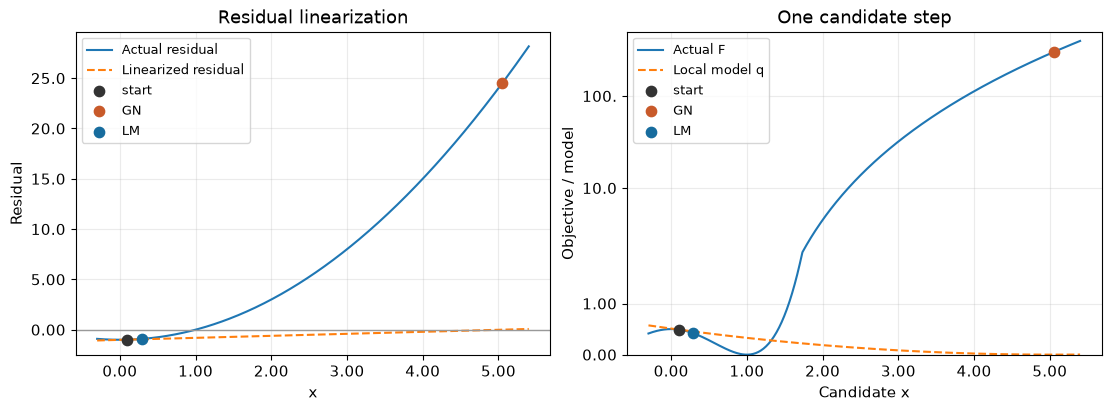

In [2]:
x0 = 0.100
r0, J0 = x0**2 - 1, 2 * x0
step_gn = -J0 * r0 / J0**2
step_lm = -J0 * r0 / (J0**2 + 1.00)
points = {"start": x0, "GN": x0 + step_gn, "LM": x0 + step_lm}
pprint({name: {"x": sig3(x), "F": sig3((x**2 - 1)**2 / 2)}
        for name, x in points.items()}, sort_dicts=False)
display(Math(r"p_{\mathrm{GN}}=-\frac{Jr}{J^2},\qquad "
             r"p_{\mathrm{LM}}=-\frac{Jr}{J^2+\lambda}"))

grid = np.linspace(-0.300, 5.40, 500)
linear_r = r0 + J0 * (grid - x0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(grid, grid**2 - 1, label="Actual residual")
axes[0].plot(grid, linear_r, "--", label="Linearized residual")
axes[0].axhline(0, color="0.600", linewidth=1)
axes[0].set(xlabel="x", ylabel="Residual", title="Residual linearization")
axes[1].plot(grid, (grid**2 - 1)**2 / 2, label="Actual F")
axes[1].plot(grid, linear_r**2 / 2, "--", label="Local model q")
axes[1].set(xlabel="Candidate x", ylabel="Objective / model",
            title="One candidate step", yscale="symlog", ylim=(-0.0100, 500))
for name, x in points.items():
    color = colors.get(name, "#333333")
    axes[0].scatter(x, x**2 - 1, s=55, color=color, zorder=3, label=name)
    axes[1].scatter(x, (x**2 - 1)**2 / 2, s=55, color=color, zorder=3, label=name)
for ax in axes:
    ax.legend(fontsize=9)
save_figure(fig, "01_scalar_step.svg")

## 5. 減衰係数を調整する実装

$\lambda$を固定して1回計算するだけでは、候補が適切かどうか分からない。実際の減少量と線形化から予測した減少量の比を使う。

$$
\begin{aligned}
\mathrm{pred}
&=q(\mathbf{0})-q(\mathbf{p})
=-\mathbf{g}^{\mathsf T}\mathbf{p}-\frac12\|\mathbf{J}\mathbf{p}\|^2,\\
\mathrm{ared}&=F(\mathbf{x})-F(\mathbf{x}+\mathbf{p}),\\
\rho&=\frac{\mathrm{ared}}{\mathrm{pred}}.
\end{aligned}
$$

分母には減衰項を含めない$q$を使う。以下の簡易LMでは、$\mathrm{pred}>0$かつ$\rho>1.00\times10^{-4}$なら候補を採用する。棄却時は現在点を変えず、$\lambda$を10倍して再試行する。採用後は$\rho>0.750$で$\lambda$を3で割り、$\rho<0.250$で2倍する。それ以外は維持する。これらの数値は実装例の設定であり、LMで一意に決まる値ではない。

更新量は次の拡大した最小二乗問題から求める。

$$
\min_{\mathbf{p}}\frac12\left\|
\begin{bmatrix}\mathbf{J}\\\sqrt{\lambda}\mathbf{I}\end{bmatrix}\mathbf{p}
-\begin{bmatrix}-\mathbf{r}\\\mathbf{0}\end{bmatrix}
\right\|^2
=\min_{\mathbf{p}}\left\{\frac12\|\mathbf{J}\mathbf{p}+\mathbf{r}\|^2
+\frac{\lambda}{2}\|\mathbf{p}\|^2\right\}.
$$

これなら逆行列や$\mathbf{J}^{\mathsf T}\mathbf{J}$を明示的に作る必要がない。列フルランクの場合、2ノルムの条件数は$\kappa_2(\mathbf{J}^{\mathsf T}\mathbf{J})=\kappa_2(\mathbf{J})^2$となるため、直接`lstsq`で解く。

終了条件は勾配の無限大ノルムが$1.00\times10^{-8}$以下、または採用した更新量が$1.00\times10^{-10}(1+\|\mathbf{x}\|)$以下である。回数上限と非有限値による停止も区別する。小さい更新量だけでは最小点への到達を保証しない。

In [3]:
def solve_ls(fun, jac, x0, method, lam0=1.00e-3, max_trials=200):
    """全ステップの GN または減衰を調整する簡易 LM を実行する。"""
    if method not in {"GN", "LM"}:
        raise ValueError("method は GN または LM を指定する")
    x = np.array(x0, dtype=float, copy=True)
    r = fun(x)
    value = float(r @ r / 2)
    lam = lam0
    path, costs, history = [x.copy()], [value], []
    status = "試行回数の上限"

    for trial in range(max_trials):
        J = jac(x)
        g = J.T @ r
        if np.linalg.norm(g, ord=np.inf) <= 1.00e-8:
            status = "勾配の条件を満たした"
            break

        # 正規方程式の逆行列を作らず、最小二乗問題を直接解く。
        damping = lam if method == "LM" else 0
        A = np.vstack([J, np.sqrt(damping) * np.eye(x.size)])
        b = np.concatenate([-r, np.zeros(x.size)])
        step = np.linalg.lstsq(A, b, rcond=None)[0]
        J_step = J @ step
        predicted = float(-g @ step - J_step @ J_step / 2)

        # 非有限値となる候補は採用しない。GN はその時点で停止する。
        with np.errstate(over="ignore", invalid="ignore"):
            r_trial = fun(x + step)
            trial_value = float(r_trial @ r_trial / 2)
        finite = np.isfinite(trial_value)
        rho = (value - trial_value) / predicted if finite and predicted > 0 else -np.inf
        accepted = bool(finite and (method == "GN" or rho > 1.00e-4))
        history.append({"trial": trial + 1, "lambda": damping, "rho": rho,
                        "accepted": accepted, "candidate_F": trial_value})

        if accepted:
            x, r, value = x + step, r_trial, trial_value
            path.append(x.copy())
        costs.append(value)  # 棄却した試行では現在値をそのまま記録する。

        if method == "LM":
            if not accepted:
                lam *= 10
            elif rho > 0.750:
                lam = max(lam / 3, 1.00e-15)
            elif rho < 0.250:
                lam *= 2
        elif not finite:
            status = "非有限値のため停止"
            break

        if accepted and np.linalg.norm(step) <= 1.00e-10 * (1 + np.linalg.norm(x)):
            status = "更新量の条件を満たした"
            break

    return {"x": x, "F": value, "path": np.array(path),
            "costs": np.array(costs), "history": history, "status": status}

## 6. 2変数の問題で反復を比較する

Rosenbrock関数の半分を最小二乗問題として書く。

$$
\mathbf{x}=\begin{bmatrix}u\\v\end{bmatrix},\quad
\mathbf{r}(\mathbf{x})=\begin{bmatrix}10(v-u^2)\\1-u\end{bmatrix},\quad
\mathbf{J}(\mathbf{x})=\begin{bmatrix}-20u&10\\-1&0\end{bmatrix},\quad
F=\frac12\{100(v-u^2)^2+(1-u)^2\}.
$$

解は$(u,v)=(1,1)$である。初期値$(-1.20,1.00)$では、

$$
\mathbf{r}_0=\begin{bmatrix}-4.40\\2.20\end{bmatrix},\quad
\mathbf{J}_0=\begin{bmatrix}24&10\\-1&0\end{bmatrix}.
$$

この例は正方で可逆なので、GNの更新量は$\mathbf{J}_0\mathbf{p}=-\mathbf{r}_0$から直接計算できる。

$$
\begin{aligned}
-p_u&=-2.20\quad\Rightarrow\quad p_u=2.20,\\
24p_u+10p_v&=4.40\quad\Rightarrow\quad
p_v=\frac{4.40-24\times2.20}{10}=-4.84,\\
\mathbf{x}_1&=\begin{bmatrix}-1.20\\1.00\end{bmatrix}
+\begin{bmatrix}2.20\\-4.84\end{bmatrix}
=\begin{bmatrix}1.00\\-3.84\end{bmatrix}.
\end{aligned}
$$

目的関数は$12.1$から$1.17\times10^3$に増える。次の更新では$p_u=0$、$10p_v=48.4$なので、$(1,1)$に達する。この例ではGNが2回で解ける一方、途中の悪化は大きい。

In [4]:
def rosen_residual(x):
    u, v = x
    return np.array([10 * (v - u**2), 1 - u])


def rosen_jacobian(x):
    u, _ = x
    return np.array([[-20 * u, 10], [-1, 0]], dtype=float)


def result_summary(result):
    """配列や小数を読みやすい出力用の辞書にまとめる。"""
    return {"x": [sig3(v) for v in result["x"]], "F": sig3(result["F"]),
            "trials": len(result["history"]), "accepted": len(result["path"]) - 1,
            "status": result["status"]}


start = np.array([-1.20, 1.00])
results = {method: solve_ls(rosen_residual, rosen_jacobian, start, method)
           for method in ["GN", "LM"]}
pprint({name: result_summary(result) for name, result in results.items()}, sort_dicts=False)

# 既知の解と、LMで採用した点の目的関数の単調性を確認する。
for result in results.values():
    np.testing.assert_allclose(result["x"], [1, 1], atol=1.00e-6)
assert np.all(np.diff(results["LM"]["costs"]) <= 0)
assert results["GN"]["costs"][1] > results["GN"]["costs"][0]

{'GN': {'x': ['1.00', '1.00'],
        'F': '1.21e-28',
        'trials': 2,
        'accepted': 2,
        'status': '勾配の条件を満たした'},
 'LM': {'x': ['1.00', '1.00'],
        'F': '1.94e-16',
        'trials': 25,
        'accepted': 19,
        'status': '勾配の条件を満たした'}}


### 更新経路と目的関数

GNは谷から大きく離れた後に解へ移動する。簡易LMは25回の試行のうち19回を採用し、6回を棄却する。図の経路には採用点だけを描き、目的関数の横軸には棄却も含む試行回数を使う。反復回数だけで計算効率を判断できないが、この例でLMの方が少ない更新で終わるわけではない。

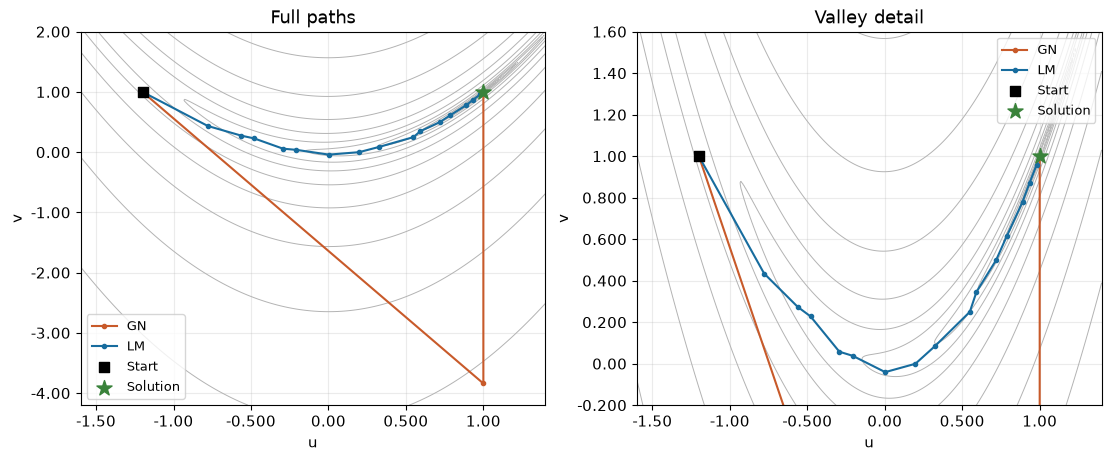

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.50), layout="constrained")
for ax, (bottom, top), title in zip(
    axes, [(-4.20, 2.00), (-0.200, 1.60)], ["Full paths", "Valley detail"]
):
    u, v = np.meshgrid(np.linspace(-1.60, 1.40, 300), np.linspace(bottom, top, 350))
    values = (100 * (v - u**2)**2 + (1 - u)**2) / 2
    ax.contour(u, v, values, levels=np.logspace(-2, 3, 12),
               colors="0.700", linewidths=0.700)
    for name, result in results.items():
        path = result["path"]
        ax.plot(path[:, 0], path[:, 1], ".-", color=colors[name], label=name)
    ax.scatter(*start, marker="s", color="black", s=45, label="Start", zorder=4)
    ax.scatter(1, 1, marker="*", color="#39823a", s=130, label="Solution", zorder=4)
    ax.set(xlim=(-1.60, 1.40), ylim=(bottom, top), xlabel="u", ylabel="v", title=title)
    ax.legend(fontsize=9)
save_figure(fig, "02_rosenbrock_paths.svg")

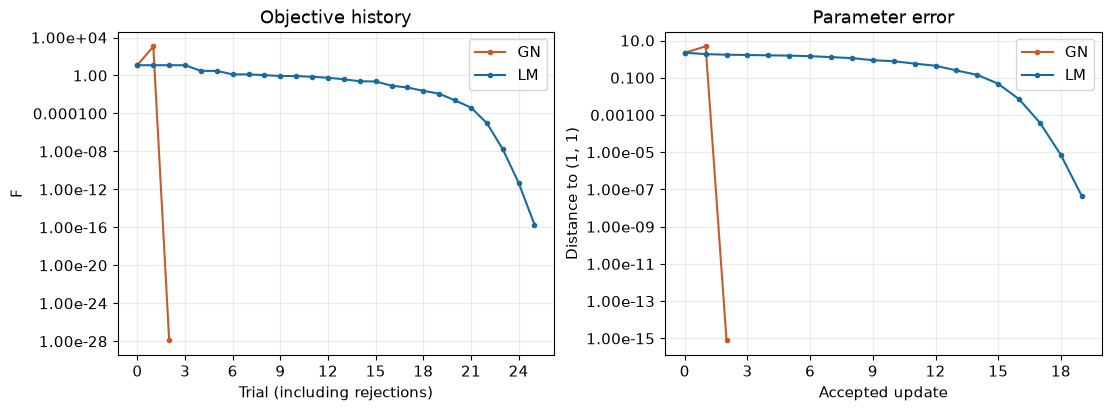

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for name, result in results.items():
    axes[0].semilogy(np.arange(result["costs"].size), result["costs"],
                     ".-", color=colors[name], label=name)
    # 右図は点の採用回数に対する解までの距離である。
    distances = np.linalg.norm(result["path"] - np.array([1, 1]), axis=1)
    axes[1].semilogy(np.arange(distances.size), distances,
                     ".-", color=colors[name], label=name)
axes[0].set(xlabel="Trial (including rejections)", ylabel="F", title="Objective history")
axes[1].set(xlabel="Accepted update", ylabel="Distance to (1, 1)", title="Parameter error")
for ax in axes:
    ax.legend()
save_figure(fig, "03_convergence.svg", integer_x=True)

### 棄却と減衰係数

次の図は、各候補の計算に使った$\lambda$と$\rho$である。赤い印は棄却を示す。$\rho<0$なら、減少を予測したのに実際には悪化している。棄却後に$\lambda$を増やし、現在点から候補を計算し直す。

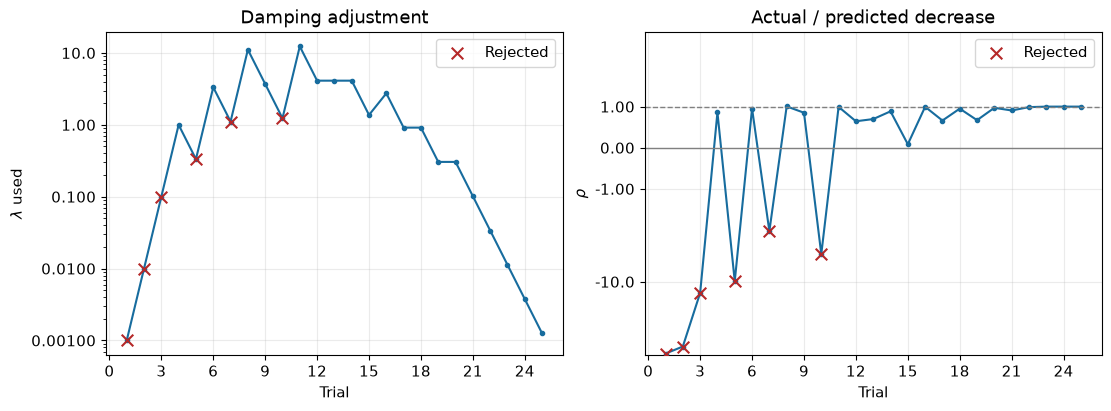

In [7]:
history = results["LM"]["history"]
trials = np.array([h["trial"] for h in history])
dampings = np.array([h["lambda"] for h in history])
ratios = np.array([h["rho"] for h in history])
rejected = np.array([not h["accepted"] for h in history])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].semilogy(trials, dampings, ".-", color=colors["LM"])
axes[0].scatter(trials[rejected], dampings[rejected], color="#b52828", marker="x", s=70,
                label="Rejected", zorder=3)
axes[0].set(xlabel="Trial", ylabel=r"$\lambda$ used", title="Damping adjustment")
axes[1].plot(trials, ratios, ".-", color=colors["LM"])
axes[1].scatter(trials[rejected], ratios[rejected], color="#b52828", marker="x", s=70,
                label="Rejected", zorder=3)
axes[1].axhline(0, color="0.500", linewidth=1)
axes[1].axhline(1, color="0.500", linestyle="--", linewidth=1)
axes[1].set(xlabel="Trial", ylabel=r"$\rho$", yscale="symlog", title="Actual / predicted decrease")
for ax in axes:
    ax.legend()
save_figure(fig, "04_damping_history.svg", integer_x=True)

## 7. 条件数とパラメータの尺度

ここでは$m\ge n$とし、$\mathbf{J}$の最大・最小特異値を$\sigma_{\max},\sigma_{\min}$とすると、

$$
\kappa_2(\mathbf{J}^{\mathsf T}\mathbf{J}+\lambda\mathbf{I})
=\frac{\sigma_{\max}^2+\lambda}{\sigma_{\min}^2+\lambda}.
$$

次の図はRosenbrockの初期点で$\lambda$だけを変えた計算である。大きくすると条件数は1に近づき、更新量は小さくなる。一方で小さすぎる更新は進みを遅くする。

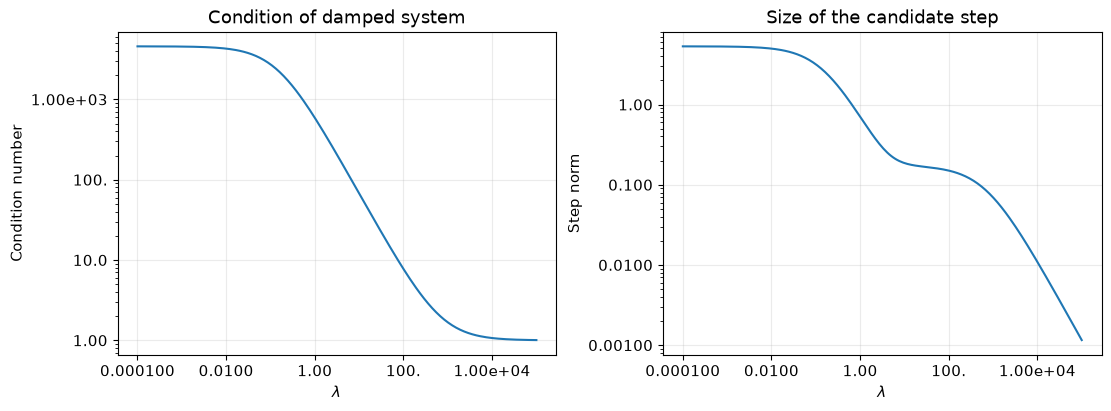

In [8]:
J = rosen_jacobian(start)
r = rosen_residual(start)
singular_values = np.linalg.svd(J, compute_uv=False)
lambda_grid = np.logspace(-4, 5, 200)
step_sizes = []
for damping in lambda_grid:
    A = np.vstack([J, np.sqrt(damping) * np.eye(2)])
    b = np.concatenate([-r, np.zeros(2)])
    step_sizes.append(np.linalg.norm(np.linalg.lstsq(A, b, rcond=None)[0]))
condition = (singular_values[0]**2 + lambda_grid) / (singular_values[-1]**2 + lambda_grid)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].loglog(lambda_grid, condition)
axes[0].set(xlabel=r"$\lambda$", ylabel="Condition number", title="Condition of damped system")
axes[1].loglog(lambda_grid, step_sizes)
axes[1].set(xlabel=r"$\lambda$", ylabel="Step norm", title="Size of the candidate step")
save_figure(fig, "05_conditioning.svg")

単位が異なるパラメータに同じ罰則を加えると、単位の選び方が更新に影響する。正の対角行列$\mathbf{D}$を使って、

$$
q_\lambda=q+\frac\lambda2\|\mathbf{D}\mathbf{p}\|^2
\quad\Rightarrow\quad
(\mathbf{J}^{\mathsf T}\mathbf{J}+\lambda\mathbf{D}^{\mathsf T}\mathbf{D})\mathbf{p}=-\mathbf{g}
$$

とする形もある。$\mathbf{D}$にはヤコビ行列の列ノルムを使うなどの選択があり、0の成分には下限が必要である。この形の大きな$\lambda$での方向は$-(\mathbf{D}^{\mathsf T}\mathbf{D})^{-1}\mathbf{g}$となる。

LMは$\|\mathbf{D}\mathbf{p}\|\le\Delta$という信頼領域内で$q$を最小化する考え方と対応する。ここで$\Delta$は更新を許す範囲の半径であり、$\lambda$は制約の強さに対応する。調整法や尺度の選択は実装によって異なる。[Ceres Solverの解説](https://ceres-solver.readthedocs.io/latest/nnls_solving.html#levenberg-marquardt)もこの形を扱っている。

減衰項が抑えるのは各反復の更新量である。元の目的関数に固定の$\lambda\|\mathbf{x}\|^2/2$を加えるリッジ正則化とは区別する。どちらの手法も、一般の非線形問題で大域的な最小値を保証するものではない。

## 8. 指数関数の当てはめ

次に$y_i\approx a e^{-b t_i}$を考える。$\mathbf{x}=(a,b)^{\mathsf T}$とすれば、残差とヤコビ行列の各行は次のとおりである。

$$
\begin{aligned}
r_i&=a e^{-bt_i}-y_i,\\
\frac{\partial r_i}{\partial a}&=e^{-bt_i},\\
\frac{\partial r_i}{\partial b}&=a e^{-bt_i}(-t_i)=-a t_i e^{-bt_i},\\
\mathbf{J}_{i,:}&=\begin{bmatrix}e^{-bt_i}&-a t_i e^{-bt_i}\end{bmatrix}.
\end{aligned}
$$

$a=2.50$、$b=1.30$で生成した40点に、標準偏差$0.0500$の正規乱数を加える。乱数シードは104に固定する。初期値は$(1.00,0.500)$と$(0.100,4.00)$の二つを使う。

In [9]:
rng = np.random.default_rng(104)
t = np.linspace(0, 4, 40)
y = 2.50 * np.exp(-1.30 * t) + rng.normal(0, 0.0500, t.size)


def exp_model(x, times):
    a, b = x
    return a * np.exp(-b * times)


def exp_residual(x):
    return exp_model(x, t) - y


def exp_jacobian(x):
    a, b = x
    decay = np.exp(-b * t)
    return np.column_stack([decay, -a * t * decay])


# 解析的なヤコビ行列を中心差分でも確認する。
check_point = np.array([1.00, 0.500])
h = 1.00e-6
directions = h * np.eye(2)
finite_difference = np.column_stack([
    (exp_residual(check_point + d) - exp_residual(check_point - d)) / (2 * h)
    for d in directions
])
np.testing.assert_allclose(exp_jacobian(check_point), finite_difference,
                           rtol=1.00e-7, atol=1.00e-9)

initials = {"near": [1.00, 0.500], "far": [0.100, 4.00]}
fits = {(case, method): solve_ls(exp_residual, exp_jacobian, initial, method)
        for case, initial in initials.items() for method in ["GN", "LM"]}
pprint({f"{case} / {method}": result_summary(result)
        for (case, method), result in fits.items()}, sort_dicts=False)

{'near / GN': {'x': ['2.50', '1.27'],
               'F': '0.0406',
               'trials': 6,
               'accepted': 6,
               'status': '勾配の条件を満たした'},
 'near / LM': {'x': ['2.50', '1.27'],
               'F': '0.0406',
               'trials': 6,
               'accepted': 6,
               'status': '勾配の条件を満たした'},
 'far / GN': {'x': ['0.100', '4.00'],
              'F': '13.1',
              'trials': 1,
              'accepted': 0,
              'status': '非有限値のため停止'},
 'far / LM': {'x': ['2.50', '1.27'],
              'F': '0.0406',
              'trials': 11,
              'accepted': 8,
              'status': '勾配の条件を満たした'}}


近い初期値では両手法とも同じ解に達する。遠い初期値ではGNの最初の候補で指数関数の計算が非有限値となり、実装は停止する。LMは候補を棄却して続け、$a\approx2.50$、$b\approx1.27$、$F\approx0.0406$を得る。図の「far / GN stopped」は停止時に保持していた初期値であり、推定に成功した曲線ではない。

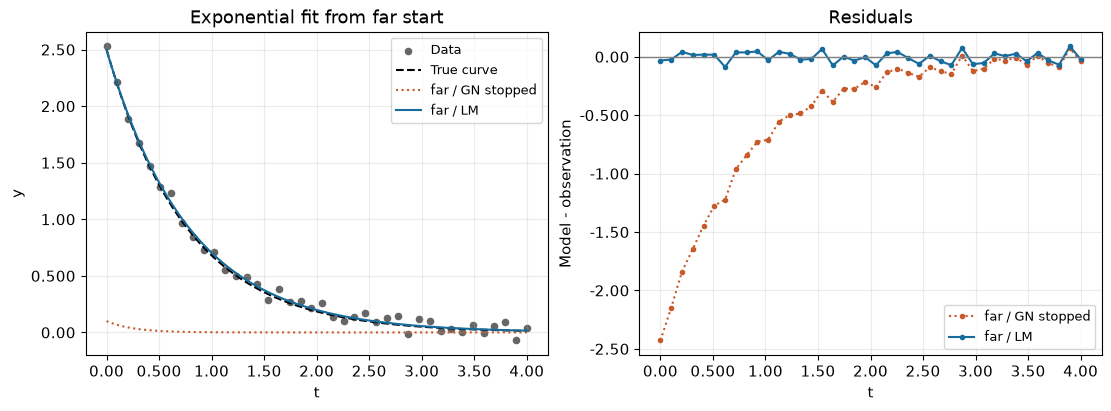

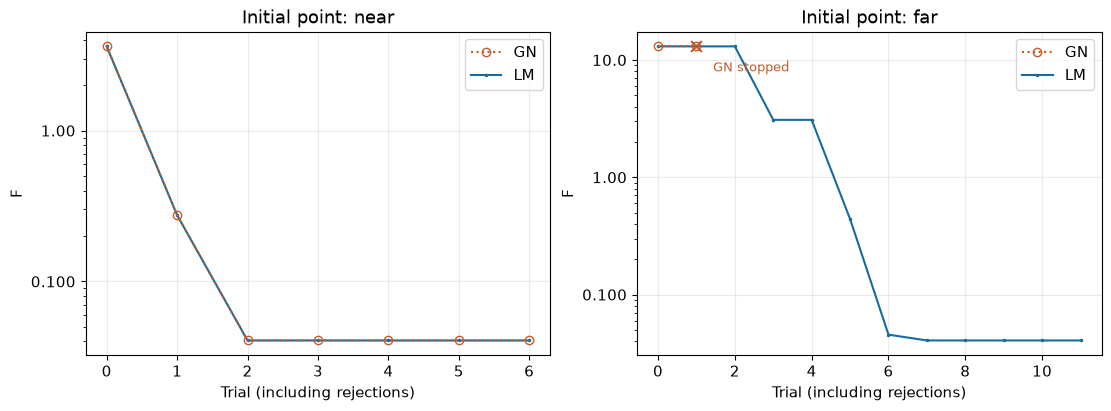

In [10]:
dense_t = np.linspace(0, 4, 250)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].scatter(t, y, s=20, color="0.400", label="Data")
axes[0].plot(dense_t, 2.50 * np.exp(-1.30 * dense_t), "--", color="black", label="True curve")
for method, style in [("GN", ":"), ("LM", "-")]:
    x_fit = fits[("far", method)]["x"]
    label = "far / GN stopped" if method == "GN" else "far / LM"
    axes[0].plot(dense_t, exp_model(x_fit, dense_t), style, color=colors[method], label=label)
    axes[1].plot(t, exp_residual(x_fit), "." + style, color=colors[method], label=label)
axes[0].set(xlabel="t", ylabel="y", title="Exponential fit from far start")
axes[1].axhline(0, color="0.500", linewidth=1)
axes[1].set(xlabel="t", ylabel="Model - observation", title="Residuals")
for ax in axes:
    ax.legend(fontsize=9)
save_figure(fig, "06_exponential_fit.svg")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, case in zip(axes, initials):
    for method, style in [("GN", ":"), ("LM", "-")]:
        result = fits[(case, method)]
        # 同じ曲線が重なっても区別できるよう、GNは白抜きの丸にする。
        ax.semilogy(
            np.arange(result["costs"].size), result["costs"], linestyle=style,
            marker="o" if method == "GN" else ".", markersize=6 if method == "GN" else 3,
            markerfacecolor="none" if method == "GN" else colors[method],
            color=colors[method], label=method, zorder=3 if method == "GN" else 2,
        )
        if result["status"] == "非有限値のため停止":
            last_trial = result["costs"].size - 1
            ax.scatter(last_trial, result["F"], marker="x", s=60, color=colors[method], zorder=4)
            ax.annotate("GN stopped", (last_trial, result["F"]), xytext=(12, -18),
                        textcoords="offset points", color=colors[method], fontsize=9)
    ax.set(xlabel="Trial (including rejections)", ylabel="F", title=f"Initial point: {case}")
    ax.legend()
save_figure(fig, "07_initial_values.svg", integer_x=True)

### SciPyのLM法との照合

`scipy.optimize.least_squares`に渡すのは二乗和ではなく残差ベクトルである。`method="lm"`はMINPACKを利用し、上の簡易実装とは減衰の調整や停止条件が異なる。既定値に依存しないよう、この例では`x_scale=1`を指定する。

SciPyのLMは境界制約と疎なヤコビ行列に対応せず、$m<n$の問題も扱えない。また損失は`linear`に限られる。これはSciPyの当該インターフェースの制約である。境界を指定する場合は`method="trf"`などを選ぶ。[SciPy公式ドキュメント](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html)

In [11]:
reference = least_squares(
    exp_residual, initials["far"], jac=exp_jacobian, method="lm", x_scale=1,
    ftol=1.00e-12, xtol=1.00e-12, gtol=1.00e-12,
)
pprint({"x": [sig3(v) for v in reference.x], "F": sig3(reference.cost),
        "nfev": reference.nfev, "success": bool(reference.success)}, sort_dicts=False)

# 反復回数ではなく、同じ目的関数の解と勾配で照合する。
assert reference.success
for key in [("near", "GN"), ("near", "LM"), ("far", "LM")]:
    np.testing.assert_allclose(fits[key]["x"], reference.x, atol=1.00e-6)
    gradient = exp_jacobian(fits[key]["x"]).T @ exp_residual(fits[key]["x"])
    assert np.linalg.norm(gradient, ord=np.inf) < 1.00e-7
for case in initials:
    assert np.all(np.diff(fits[(case, "LM")]["costs"]) <= 0)
assert fits[("far", "GN")]["status"] == "非有限値のため停止"

display(Math(r"\widehat{\mathbf{x}}=\begin{bmatrix}"
             + sig3(reference.x[0]) + r"\\" + sig3(reference.x[1])
             + r"\end{bmatrix},\qquad F(\widehat{\mathbf{x}})=" + sig3(reference.cost)))
print("既知の解、ヤコビ行列、採用点の目的関数、SciPyとの一致を確認した。")

{'x': ['2.50', '1.27'], 'F': '0.0406', 'nfev': 10, 'success': True}


<IPython.core.display.Math object>

既知の解、ヤコビ行列、採用点の目的関数、SciPyとの一致を確認した。


## 結論

この記事では、GN法とLM法の更新式を導出し、減衰項による更新量の調整と候補の採否の違いを数値例で確認した。

GN法は残差を線形化した最小二乗問題を解く。LM法はその問題に更新量の罰則を加え、実際の誤差の減少を確認しながら減衰を調整する。解に近い場合はGNが少ない更新で進むことがあるが、初期値から大きく移動する場面ではLMの棄却と再試行が役立つ。私は最終的な推定値だけでなく、目的関数と停止理由も確認する方がよいと考える。

### 参考文献

- [SciPy: least_squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html) — API、MINPACK、各手法の制約。
- [Ceres Solver: Solving Non-linear Least Squares](https://ceres-solver.readthedocs.io/latest/nnls_solving.html) — 線形化、信頼領域、LMの減衰項。